In [1]:
# ==========================================================
# Resume-JD Match Scorer using Siamese BiLSTM
# TensorFlow / Keras Implementation
# ==========================================================

import json
import random
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

import tensorflow as tf

from tensorflow.keras.layers import (
    Input,
    TextVectorization,
    Embedding,
    Bidirectional,
    LSTM,
    GlobalMaxPooling1D,
    Dense,
    Dropout,
    Concatenate,
    Lambda,
    Multiply
)

from tensorflow.keras.models import Model

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [3]:
MODEL_PATH = Path("models")
RESULT_PATH = Path("results")

MODEL_PATH.mkdir(exist_ok=True)

RESULT_PATH.mkdir(exist_ok=True)

In [4]:
def load_jsonl(file_path):

    dataset = []

    with open(file_path, "r", encoding="utf-8") as file:

        for line in file:

            if line.strip():

                dataset.append(json.loads(line))

    return dataset

In [5]:
from google.colab import files

uploaded = files.upload()

DATA_FILE = next(iter(uploaded.keys()))

Saving train.jsonl to train (1).jsonl


In [6]:
records = load_jsonl(DATA_FILE)

print(f"Total Records : {len(records)}")

print()

print("Columns Available:")

print(records[0].keys())

Total Records : 50000

Columns Available:
dict_keys(['Job-Description', 'Resume-matched', 'Resume-unmatched', 'Skills', 'Experiences', 'Experiences-years', 'Filtered-information'])


In [7]:
# Match Labels
LABELS = {
    0: "Weak Match",
    1: "Medium Match",
    2: "Strong Match"
}

In [8]:
def normalize_text(text):
    """
    Performs basic cleaning before vectorization.
    """

    text = str(text)

    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [9]:
def create_training_dataset(records, seed=42):

    rng = random.Random(seed)

    # Collect all matched resumes
    matched_resume_pool = [
        normalize_text(item["Resume-matched"])
        for item in records
    ]

    # Create shuffled resumes for Weak class
    weak_resume_pool = matched_resume_pool.copy()
    rng.shuffle(weak_resume_pool)

    # Prevent same resume appearing in Weak pair
    for i in range(len(matched_resume_pool)):
        if weak_resume_pool[i] == matched_resume_pool[i]:
            swap_index = (i + 1) % len(matched_resume_pool)

            weak_resume_pool[i], weak_resume_pool[swap_index] = (
                weak_resume_pool[swap_index],
                weak_resume_pool[i],
            )

    dataset = []

    for index, sample in enumerate(records):

        job_description = normalize_text(sample["Job-Description"])

        # Strong Match
        dataset.append({
            "resume_text": normalize_text(sample["Resume-matched"]),
            "job_description": job_description,
            "match_label": 2,
            "label_name": LABELS[2]
        })

        # Medium Match
        dataset.append({
            "resume_text": normalize_text(sample["Resume-unmatched"]),
            "job_description": job_description,
            "match_label": 1,
            "label_name": LABELS[1]
        })

        # Weak Match
        dataset.append({
            "resume_text": weak_resume_pool[index],
            "job_description": job_description,
            "match_label": 0,
            "label_name": LABELS[0]
        })

    return pd.DataFrame(dataset)

In [10]:
training_df = create_training_dataset(records)

print("Total Training Samples :", len(training_df))

training_df.head()

Total Training Samples : 150000


,resume_text,job_description,match_label,label_name
0,## Personal Information Name: Konstantina Caru...,## Job Title Oracle SCM Developer ## Job Summa...,2,Strong Match
1,## Personal Information Name: Konstantina Caru...,## Job Title Oracle SCM Developer ## Job Summa...,1,Medium Match
2,Personal Information Name: Nino Vanderbeek Ema...,## Job Title Oracle SCM Developer ## Job Summa...,0,Weak Match
3,## Personal Information Name: Yelena Belova Em...,"## Job Title Electrical, Electronic, and Elect...",2,Strong Match
4,## Personal Information Name: Yelena Belova Em...,"## Job Title Electrical, Electronic, and Elect...",1,Medium Match


In [11]:
training_df = training_df.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

In [12]:
print(training_df["label_name"].value_counts())

print()

print(training_df["match_label"].value_counts())

label_name
Medium Match    50000
Weak Match      50000
Strong Match    50000
Name: count, dtype: int64

match_label
1    50000
0    50000
2    50000
Name: count, dtype: int64


In [13]:
print(training_df.info())

print()

training_df.sample(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 4 columns):
 #   Column           Non-Null Count   Dtype 
---  ------           --------------   ----- 
 0   resume_text      150000 non-null  object
 1   job_description  150000 non-null  object
 2   match_label      150000 non-null  int64 
 3   label_name       150000 non-null  object
dtypes: int64(1), object(3)
memory usage: 4.6+ MB
None



,resume_text,job_description,match_label,label_name
59770,##### Personal Information - Name: Trinidad Ji...,##### Job title Java/Scala Developer ##### Job...,1,Medium Match
21362,## Personal Information Name: Ofentse Motsepe ...,## Job title Junior C#.NET Developer ## Job Su...,2,Strong Match
127324,## Personal Information Name: Sebastian Tennan...,## Job Title Testing Engineer (Kiosk) ## Job S...,1,Medium Match
140509,## Personal Information Name: Kirollos Ibrahim...,## Job title Financial Analyst (excel expert) ...,2,Strong Match
144297,## Personal Information Name: Noam Davis Email...,## Job Title Healthcare Social Worker ## Job S...,1,Medium Match


In [14]:
train_df, temp_df = train_test_split(
    training_df,
    test_size=0.20,
    random_state=SEED,
    stratify=training_df["match_label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["match_label"]
)

print(f"Training Samples   : {len(train_df)}")
print(f"Validation Samples : {len(val_df)}")
print(f"Testing Samples    : {len(test_df)}")

Training Samples   : 120000
Validation Samples : 15000
Testing Samples    : 15000


In [15]:
MAX_VOCAB_SIZE = 30000
MAX_SEQUENCE_LENGTH = 320
EMBEDDING_DIM = 128
BATCH_SIZE = 32

In [16]:
text_vectorizer = TextVectorization(
    max_tokens=MAX_VOCAB_SIZE,
    output_mode="int",
    output_sequence_length=MAX_SEQUENCE_LENGTH,
    standardize="lower_and_strip_punctuation"
)

In [17]:
training_text = pd.concat(
    [
        train_df["resume_text"],
        train_df["job_description"]
    ],
    ignore_index=True
)

text_vectorizer.adapt(training_text)

VOCAB_SIZE = len(text_vectorizer.get_vocabulary())

print(f"Vocabulary Size : {VOCAB_SIZE}")

Vocabulary Size : 30000


In [18]:
def create_tf_dataset(dataframe,
                      batch_size=32,
                      shuffle=False):

    resume = dataframe["resume_text"].astype(str).values

    jd = dataframe["job_description"].astype(str).values

    labels = dataframe["match_label"].astype("int32").values

    dataset = tf.data.Dataset.from_tensor_slices(
        (
            {
                "resume_input": resume,
                "jd_input": jd
            },
            labels
        )
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED
        )

    dataset = dataset.batch(batch_size)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

In [19]:
train_dataset = create_tf_dataset(
    train_df,
    batch_size=BATCH_SIZE,
    shuffle=True
)

validation_dataset = create_tf_dataset(
    val_df,
    batch_size=BATCH_SIZE
)

test_dataset = create_tf_dataset(
    test_df,
    batch_size=BATCH_SIZE
)

In [20]:
print(train_dataset)

print(validation_dataset)

print(test_dataset)

<_PrefetchDataset element_spec=({'resume_input': TensorSpec(shape=(None,), dtype=tf.string, name=None), 'jd_input': TensorSpec(shape=(None,), dtype=tf.string, name=None)}, TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
<_PrefetchDataset element_spec=({'resume_input': TensorSpec(shape=(None,), dtype=tf.string, name=None), 'jd_input': TensorSpec(shape=(None,), dtype=tf.string, name=None)}, TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
<_PrefetchDataset element_spec=({'resume_input': TensorSpec(shape=(None,), dtype=tf.string, name=None), 'jd_input': TensorSpec(shape=(None,), dtype=tf.string, name=None)}, TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


In [21]:
for (features, labels) in train_dataset.take(1):

    print("Resume Batch Shape :",
          features["resume_input"].shape)

    print("JD Batch Shape :",
          features["jd_input"].shape)

    print("Labels Shape :",
          labels.shape)

Resume Batch Shape : (32,)
JD Batch Shape : (32,)
Labels Shape : (32,)


In [22]:
def build_resume_jd_matcher(vocab_size, embedding_dim=128):

    resume_input = Input(shape=(), dtype=tf.string, name="resume_input")
    jd_input = Input(shape=(), dtype=tf.string, name="jd_input")

    shared_embedding = Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        mask_zero=True,
        name="shared_embedding"
    )

    shared_bilstm = Bidirectional(
        LSTM(64, return_sequences=True),
        name="shared_bilstm"
    )

    pooling_layer = GlobalMaxPooling1D(name="global_pooling")

    def encoder(text):

        x = text_vectorizer(text)
        x = shared_embedding(x)
        x = shared_bilstm(x)
        x = pooling_layer(x)

        return x

    resume_vector = encoder(resume_input)
    jd_vector = encoder(jd_input)

    absolute_difference = Lambda(
        lambda x: tf.abs(x[0] - x[1]),
        name="absolute_difference"
    )([resume_vector, jd_vector])

    elementwise_product = Multiply(
        name="elementwise_product"
    )([resume_vector, jd_vector])

    comparison_features = Concatenate(
        name="comparison_features"
    )([
        resume_vector,
        jd_vector,
        absolute_difference,
        elementwise_product
    ])

    x = Dense(128, activation="relu")(comparison_features)
    x = Dropout(0.30)(x)
    x = Dense(64, activation="relu")(x)

    output = Dense(
        3,
        activation="softmax",
        name="match_prediction"
    )(x)

    model = Model(
        inputs=[resume_input, jd_input],
        outputs=output,
        name="Resume_JD_Siamese_BiLSTM"
    )

    return model

In [23]:
model = build_resume_jd_matcher(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM
)

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'global_pooling' (of type GlobalMaxPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Model: "Resume_JD_Siamese_BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ resume_input        │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ jd_input            │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 320)       │          0 │ resume_input[0][… │
│ (TextVectorization) │                   │            │ jd_input[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_embedding    │ (None, 320, 128)  │  3,840,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │ text_vectorizati… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 320)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 320)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_bilstm       │ (None, 320, 128)  │     98,816 │ shared_embedding… │
│ (Bidirectional)     │                   │            │ not_equal[0][0],  │
│                     │                   │            │ shared_embedding… │
│                     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_pooling      │ (None, 128)       │          0 │ shared_bilstm[0]… │
│ (GlobalMaxPooling1… │                   │            │ shared_bilstm[1]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ absolute_difference │ (None, 128)       │          0 │ global_pooling[0… │
│ (Lambda)            │                   │            │ global_pooling[1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ elementwise_product │ (None, 128)       │          0 │ global_pooling[0… │
│ (Multiply)          │                   │            │ global_pooling[1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ comparison_features │ (None, 512)       │          0 │ global_pooling[0… │
│ (Concatenate)       │                   │            │ global_pooling[1… │
│                     │                   │            │ absolute_differe… │
│                     │                   │            │ elementwise_prod… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     65,664 │ comparison_featu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      8,256 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ match_prediction    │ (None, 3)         │        195 │ dense_1[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,012,931 (15.31 MB)

 Trainable params: 4,012,931 (15.31 MB)

 Non-trainable params: 0 (0.00 B)

Train Model

In [24]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    filepath=MODEL_PATH / "resume_jd_match_model.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [26]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=12,
    callbacks=[early_stop, checkpoint],
    verbose=1
)

Epoch 1/12
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.7654 - loss: 0.4700
Epoch 1: val_loss improved from None to 0.32094, saving model to models/resume_jd_match_model.keras

Epoch 1: finished saving model to models/resume_jd_match_model.keras
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 158s 42ms/step - accuracy: 0.8028 - loss: 0.4085 - val_accuracy: 0.8513 - val_loss: 0.3209
Epoch 2/12
3749/3750 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.8762 - loss: 0.2805
Epoch 2: val_loss improved from 0.32094 to 0.28742, saving model to models/resume_jd_match_model.keras

Epoch 2: finished saving model to models/resume_jd_match_model.keras
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 155s 41ms/step - accuracy: 0.8759 - loss: 0.2806 - val_accuracy: 0.8730 - val_loss: 0.2874
Epoch 3/12
3749/3750 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.9146 - loss: 0.2078
Epoch 3: val_loss improved from 0.28742 to 0.27563, saving model to models/resume_jd_match_model.keras

Epoch 3: finished saving model to models/r

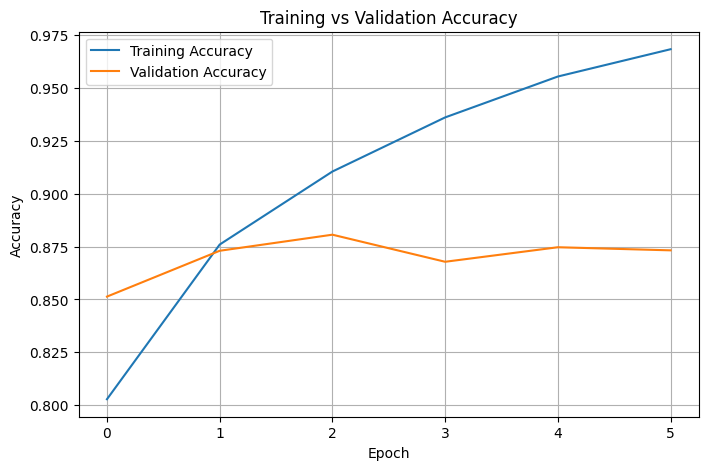

In [27]:
plt.figure(figsize=(8,5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")

plt.legend()

plt.grid(True)

plt.show()

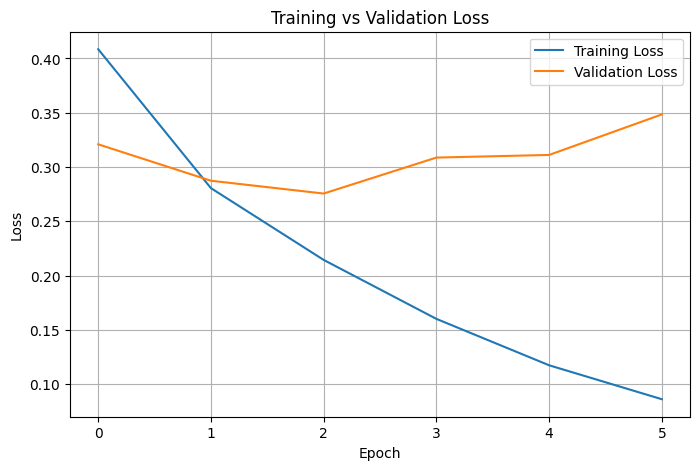

In [28]:
plt.figure(figsize=(8,5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()

plt.grid(True)

plt.show()

Evaluate

In [29]:
# Evaluate model performance on the test dataset
test_loss, test_accuracy = model.evaluate(
    test_dataset,
    verbose=1
)

print(f"\nTest Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")

469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.8699 - loss: 0.2868

Test Loss     : 0.2868
Test Accuracy : 0.8699


In [30]:
# Generate prediction probabilities
prediction_probabilities = model.predict(
    test_dataset,
    verbose=1
)

# Convert probabilities into class labels
predicted_labels = np.argmax(
    prediction_probabilities,
    axis=1
)

# Actual labels
true_labels = test_df["match_label"].to_numpy()

469/469 ━━━━━━━━━━━━━━━━━━━━ 13s 26ms/step


In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(
    true_labels,
    predicted_labels
)

precision = precision_score(
    true_labels,
    predicted_labels,
    average="macro"
)

recall = recall_score(
    true_labels,
    predicted_labels,
    average="macro"
)

f1 = f1_score(
    true_labels,
    predicted_labels,
    average="macro"
)

print("=" * 50)
print(" Resume-JD Match Scorer Performance")
print("=" * 50)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

print("=" * 50)

 Resume-JD Match Scorer Performance
Accuracy : 0.8699
Precision: 0.8733
Recall   : 0.8699
F1 Score : 0.8695


In [38]:
COMMON_SKILLS = [
    "python","java","sql","javascript","html","css",
    "react","node","fastapi","flask",
    "docker","kubernetes",
    "aws","azure","gcp",
    "tensorflow","keras","pytorch",
    "machine learning","deep learning",
    "nlp","rag","vector database",
    "mongodb","mysql","postgresql",
    "spark","hadoop",
    "linux","git","github",
    "power bi","tableau","excel"
]

In [39]:
def extract_skills(text):

    text = str(text).lower()

    skills = []

    for skill in COMMON_SKILLS:

        if skill in text:
            skills.append(skill)

    return sorted(list(set(skills)))

In [40]:
CLASS_NAMES = {
    0: "Weak Match",
    1: "Medium Match",
    2: "Strong Match"
}


def predict_resume_match(resume_text, job_description):

    resume_text = str(resume_text)
    job_description = str(job_description)

    prediction = model.predict(
        {
            "resume_input": tf.constant([resume_text]),
            "jd_input": tf.constant([job_description])
        },
        verbose=0
    )

    probabilities = prediction[0]

    predicted_class = int(np.argmax(probabilities))

    confidence = float(probabilities[predicted_class])

    resume_skills = set(extract_skills(resume_text))

    jd_skills = set(extract_skills(job_description))

    common = sorted(resume_skills & jd_skills)

    missing = sorted(jd_skills - resume_skills)

    return {

        "Predicted Label": CLASS_NAMES[predicted_class],

        "Confidence": confidence,

        "Probabilities": probabilities,

        "Common Skills": common,

        "Missing Skills": missing
    }

In [41]:
sample = test_df.sample(
    n=1,
    random_state=SEED
).iloc[0]

prediction = predict_resume_match(
    sample["resume_text"],
    sample["job_description"]
)

print("="*60)
print("Resume-JD Match Prediction")
print("="*60)

print("Prediction :", prediction["Predicted Label"])

print(f"Confidence : {prediction['Confidence']:.2%}")

print()

print("Common Skills")

print(prediction["Common Skills"])

print()

print("Missing Skills")

print(prediction["Missing Skills"])

print("="*60)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'global_pooling' (of type GlobalMaxPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Resume-JD Match Prediction
Prediction : Medium Match
Confidence : 78.71%

Common Skills
[]

Missing Skills
['excel', 'sql']


In [42]:
print("Prediction Probabilities")

print()

for i in range(3):

    print(
        f"{CLASS_NAMES[i]} : "
        f"{prediction['Probabilities'][i]:.2%}"
    )

Prediction Probabilities

Weak Match : 0.03%
Medium Match : 78.71%
Strong Match : 21.27%


In [43]:
model.save(
    MODEL_PATH / "resume_jd_match_model_final.keras"
)

print("Model Saved Successfully")

Model Saved Successfully
